# RNN assignment · test an idea fairly

Predict the next trading session's Google opening price from a short history of opening prices. This historical teaching example demonstrates sequence preparation and evaluation; it does not establish a profitable trading strategy.

**Outcome:** explain the input shape, keep future information out of fitting, train a compact
recurrent model, and compare it with a simple baseline on identical target dates.

**Suggested time:** 20–30 minutes after the walkthrough.
This is a runnable starter. The working pipeline is supplied; your work is the experiment, evidence and explanation in the learner response cells. The final test is gated until you finish validation.


In [1]:
import os
from pathlib import Path

# This must happen before importing keras. Restart the kernel to change backend.
os.environ.setdefault("KERAS_BACKEND", "torch")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error

SEED = 42
np.random.seed(SEED)
plt.rcParams.update({"figure.figsize": (10, 4), "axes.grid": True})
print("Configured Keras backend:", os.environ["KERAS_BACKEND"])


Configured Keras backend: torch


## Your core tasks

1. **Trace one example.** Before running the model, write the three dimensions of `X_train`,
   explain `UNITS`, and identify the input dates and target date of the first validation example.
   Explain why the first test input can use December history.
2. **Make a prediction before experimenting.** Compare the supplied 20-day window with **one**
   of 10 or 50 trading days. Write a hypothesis, then change only `LOOKBACK`. Keep the split,
   seed, units, optimizer and stopping rule fixed. Re-run sections 1–6 for each configuration.
3. **Record evidence.** Fill the experiment table with both validation MAE/RMSE, epochs run,
   and the unchanged persistence baseline. Report whether any model beats it.
4. **Choose and freeze.** Choose the neural configuration by validation MAE, state the decision,
   then re-run sections 1–6 with that configuration. Set `RUN_FINAL_TEST = True` once.
   Report final model and persistence scores and one limitation.

**Success criteria:** two controlled runs; correct shapes and target dates; original-unit
metrics; honest baseline comparison; a frozen final configuration; no tuning using test scores.
A lower score than the baseline is not a completion requirement.

**Hint:** increasing the window changes the number of eligible training samples, but our
validation/test target dates stay fixed. Look at `target_pos`, not the number of CSV rows alone.


## 1 · Load the original dated observations and choose a small configuration


In [2]:
# Change one setting at a time during the core experiment.
LOOKBACK = 20
UNITS = 16
MAX_EPOCHS = 30
BATCH_SIZE = 32
LEARNING_RATE = 0.001


In [3]:
# Leave as None when using the complete pack. Otherwise point to your CSV folder.
DATA_DIR = None  # Example: Path("/path/to/bootcamp/data")

def data_file(filename, dataset_handle):
    """Prefer the supplied CSV; use the exact public dataset version if needed."""
    roots = ([Path(DATA_DIR).expanduser()] if DATA_DIR is not None else
             [Path("data"), Path("../data"), Path("../../data"), Path(".")])
    for folder in roots:
        candidate = folder / filename
        if candidate.is_file():
            return candidate.resolve()
    try:
        import kagglehub
        folder = Path(kagglehub.dataset_download(dataset_handle))
    except Exception as exc:
        raise RuntimeError(
            f"Cannot locate {filename}. Extract the full pack or set DATA_DIR. "
            "The fallback needs kagglehub, internet access and any access "
            "requirements requested by Kaggle. No replacement data is generated."
        ) from exc
    candidate = folder / filename
    if not candidate.is_file():
        raise FileNotFoundError(f"Expected CSV is missing: {candidate}")
    return candidate


In [4]:
stock_handle = "rahulsah06/gooogle-stock-price/versions/1"

def read_stock(file):
    frame = pd.read_csv(file, usecols=["Date", "Open"])
    frame["Date"] = pd.to_datetime(frame["Date"], format="%m/%d/%Y", errors="raise")
    frame["Open"] = pd.to_numeric(frame["Open"], errors="raise")
    frame = frame.sort_values("Date").set_index("Date")
    if frame.index.has_duplicates or not np.isfinite(frame["Open"]).all():
        raise ValueError("Stock data contains duplicate dates or invalid prices.")
    if not (frame["Open"] > 0).all():
        raise ValueError("Expected positive opening prices.")
    return frame

historical = read_stock(data_file("Google_Stock_Price_Train.csv", stock_handle))
holdout = read_stock(data_file("Google_Stock_Price_Test.csv", stock_handle))
assert historical.index.max() < holdout.index.min(), "Historical and test dates overlap."
series = pd.concat([historical, holdout])
values = series[["Open"]].to_numpy(dtype="float32")
dates = series.index
train_end = int(len(historical) * 0.8)
val_end = len(historical)
assert LOOKBACK < train_end < val_end < len(values)

print("Historical rows:", len(historical), "| Held-out trading days:", len(holdout))
print("Dates:", dates.min().date(), "to", dates.max().date())
historical.head()


Historical rows: 1258 | Held-out trading days: 20
Dates: 2012-01-03 to 2017-01-31


,Open
Date,
2012-01-03,325.25
2012-01-04,331.27
2012-01-05,329.83
2012-01-06,328.34
2012-01-09,322.04


## 2 · Split chronologically, then fit the scaler

Training dates come first, validation dates next, and test dates last. Validation is used for
early stopping and configuration choices. Test labels are used only for the final report.

Fit the scaler using the **training period only**, including the historical context needed
for its first window. Apply that same fitted scaler everywhere. A validation or test value
may transform outside `[0, 1]` when it exceeds the training range; do not refit or clip it to
hide that change. The Dense output is linear, so predictions are not restricted to `[0, 1]`.
See [scikit-learn's leakage guidance](https://scikit-learn.org/stable/common_pitfalls.html#data-leakage).


            Period First date  Last date  Rows
  Training history 2012-01-03 2015-12-31  1006
Validation targets 2016-01-04 2016-12-30   252
      Test targets 2017-01-03 2017-01-31    20
Scaler minimum / maximum: [279.12] [776.6]


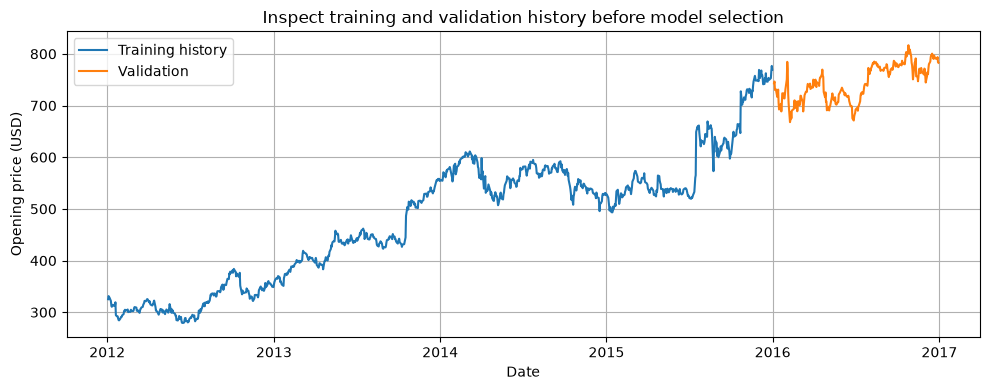

In [5]:
scaler = MinMaxScaler()
scaler.fit(values[:train_end])
scaled_values = scaler.transform(values).astype("float32")
np.testing.assert_allclose(scaler.data_min_, values[:train_end].min(axis=0))
np.testing.assert_allclose(scaler.data_max_, values[:train_end].max(axis=0))

split_summary = pd.DataFrame([
    {"Period": "Training history", "First date": dates[0].date(),
      "Last date": dates[train_end - 1].date(), "Rows": train_end},
    {"Period": "Validation targets", "First date": dates[train_end].date(),
      "Last date": dates[val_end - 1].date(), "Rows": val_end - train_end},
    {"Period": "Test targets", "First date": dates[val_end].date(),
      "Last date": dates[-1].date(), "Rows": len(values) - val_end},
])
print(split_summary.to_string(index=False))
print("Scaler minimum / maximum:", scaler.data_min_, scaler.data_max_)

plt.plot(dates[:train_end], values[:train_end, 0], label="Training history")
plt.plot(dates[train_end:val_end], values[train_end:val_end, 0], label="Validation")
plt.xlabel("Date")
plt.ylabel("Opening price (USD)")
plt.title("Inspect training and validation history before model selection")
plt.legend()
plt.tight_layout()
plt.show()


## 3 · Turn a series into supervised examples

For target position `t`, the input is `values[t - LOOKBACK:t]` and the target is `values[t]`.
The right edge of a Python slice is excluded, so the target is never inside its own input.

Keras recurrent layers receive **(samples, timesteps, features)**. Here there is one measured
feature per step. The number of recurrent units is a separate model setting.
`Input(shape=(LOOKBACK, 1))` omits the batch dimension; it does not mean one timestep with
`LOOKBACK` features. With one timestep, a stateless model sees no earlier step within that sample.

We first create all eligible windows, then assign them by **target date**. Validation/test
windows may include earlier observed values from previous splits. This preserves the first
validation and test targets instead of throwing away a whole window at each boundary.

**Evaluation contract - rolling one-step prediction:** the model and scaler stay fixed. Before
predicting time `t`, all actual observations before `t` are available. Later test predictions
therefore use earlier observed test values. This is appropriate for a forecast updated every
period; it is not a forecast of the whole test period made at its first date.


In [6]:
def make_windows(scaled_values, lookback):
    if not 1 <= lookback < len(scaled_values):
        raise ValueError("LOOKBACK must leave at least one target.")
    target_pos = np.arange(lookback, len(scaled_values))
    X = np.stack([scaled_values[t - lookback:t] for t in target_pos])
    y = scaled_values[target_pos].copy()
    return X.astype("float32"), y.astype("float32"), target_pos

X_all, y_all, target_pos = make_windows(scaled_values, LOOKBACK)
train_mask = target_pos < train_end
val_mask = (target_pos >= train_end) & (target_pos < val_end)
test_mask = target_pos >= val_end

X_train, y_train = X_all[train_mask], y_all[train_mask]
X_val, y_val = X_all[val_mask], y_all[val_mask]
X_test, y_test = X_all[test_mask], y_all[test_mask]
train_pos, val_pos, test_pos = (target_pos[mask] for mask in
                                (train_mask, val_mask, test_mask))
assert len(X_train) > 0 and len(X_val) > 0 and len(X_test) > 0
assert X_train.shape[1:] == (LOOKBACK, 1)
assert y_train.shape == (len(X_train), 1)
assert val_pos[0] == train_end and test_pos[0] == val_end
assert test_pos[-1] == len(values) - 1
np.testing.assert_allclose(X_all[0], scaled_values[:LOOKBACK])
np.testing.assert_allclose(y_all[0], scaled_values[LOOKBACK])

print("X_train / y_train:", X_train.shape, y_train.shape)
print("X_val   / y_val:  ", X_val.shape, y_val.shape)
print("X_test  / y_test: ", X_test.shape, y_test.shape)
print("First validation window:", dates[val_pos[0] - LOOKBACK].date(),
      "to", dates[val_pos[0] - 1].date(),
      "→ target", dates[val_pos[0]].date())


X_train / y_train: (986, 20, 1) (986, 1)
X_val   / y_val:   (252, 20, 1) (252, 1)
X_test  / y_test:  (20, 20, 1) (20, 1)
First validation window: 2015-12-03 to 2015-12-31 → target 2016-01-04


## 4 · Set a useful baseline before training

**Persistence** predicts the next opening price as the most recent observed opening price:
`prediction[t] = value[t - 1]`. Score it on exactly the same validation target dates as the RNN.
A curve that visually follows prices can still lose to this simple baseline.

MAE is the average absolute error. RMSE gives more weight to larger errors.
Both are reported in the original price units (USD), not scaled units. Beating the baseline
is not required to complete the lab; an honest comparison is.


In [7]:
def error_scores(actual, predicted):
    actual = np.asarray(actual).ravel()
    predicted = np.asarray(predicted).ravel()
    if actual.shape != predicted.shape:
        raise ValueError("Actual and predicted values must have identical targets.")
    return {"MAE": mean_absolute_error(actual, predicted),
            "RMSE": np.sqrt(mean_squared_error(actual, predicted))}


In [8]:
val_actual = values[val_pos, 0].copy()
val_last = values[val_pos - 1, 0].copy()
baseline_validation = pd.DataFrame(
    [error_scores(val_actual, val_last)], index=["Last observed value"]
)
baseline_validation.round(3)


,MAE,RMSE
Last observed value,7.157,9.852


## 5 · Train a small RNN

One 16-unit recurrent layer is enough to inspect this learning pipeline. More layers or
dropout are experiments, not guaranteed improvements. This is a compact teaching model.

With `return_sequences=False` (the default), the recurrent layer returns one vector of
shape `(batch, UNITS)`, and Dense maps it to `(batch, 1)`. Setting `return_sequences=True`
returns `(batch, LOOKBACK, UNITS)` and is needed when feeding a second recurrent layer.
The default setup has **305 trainable parameters**.

We pass an explicit chronological validation set. Early stopping monitors validation loss
and restores the best weights. `shuffle=False` makes the walkthrough easier to follow;
the primary protection against leakage is the chronological split and correct windows.
These models are stateless: hidden state is not carried from one sample to the next.

Documentation: [recurrent layer](https://keras.io/api/layers/recurrent_layers/simple_rnn/),
[EarlyStopping](https://keras.io/api/callbacks/early_stopping/),
[random seeds](https://keras.io/api/utils/python_utils/#set_random_seed-function).


In [9]:
import keras

keras.backend.clear_session()
keras.utils.set_random_seed(SEED)
if keras.backend.backend() == "torch":
    import torch
    torch.set_num_threads(1)  # Small CPU models rarely benefit from many threads.

print("Keras:", keras.__version__, "| Backend:", keras.backend.backend())
# Seeding supports repeatable comparisons, but exact results may differ across
# library versions, hardware and backend kernels.


Keras: 3.15.1 | Backend: torch


In [10]:
model = keras.Sequential([
    keras.Input(shape=(LOOKBACK, 1)),
    keras.layers.SimpleRNN(UNITS),
    keras.layers.Dense(1),
])
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=LEARNING_RATE),
    loss="mse"
)
model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ simple_rnn (SimpleRNN)          │ (None, 16)             │           288 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 305 (1.19 KB)

 Trainable params: 305 (1.19 KB)

 Non-trainable params: 0 (0.00 B)

Ran 30 epochs; lowest validation loss at epoch 30.


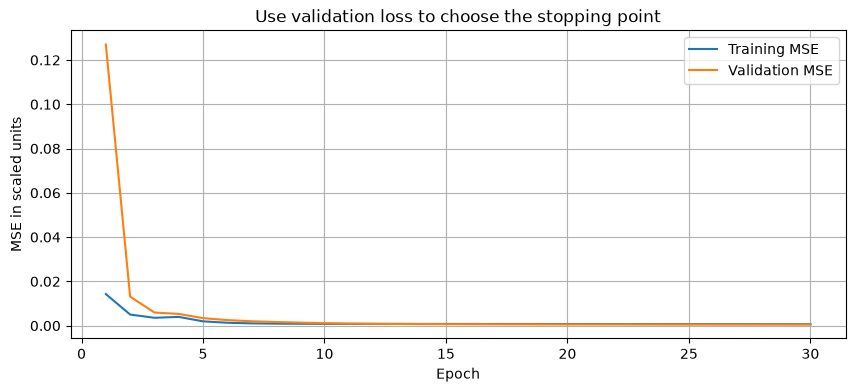

In [11]:
early_stop = keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=5, min_delta=0.0,
    restore_best_weights=True
)
history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=MAX_EPOCHS, batch_size=BATCH_SIZE,
    shuffle=False, callbacks=[early_stop], verbose=0
)
best_epoch = int(np.argmin(history.history["val_loss"])) + 1
print(f"Ran {len(history.history['loss'])} epochs; lowest validation loss at epoch {best_epoch}.")

epochs = np.arange(1, len(history.history["loss"]) + 1)
plt.plot(epochs, history.history["loss"], label="Training MSE")
plt.plot(epochs, history.history["val_loss"], label="Validation MSE")
plt.xlabel("Epoch")
plt.ylabel("MSE in scaled units")
plt.title("Use validation loss to choose the stopping point")
plt.legend()
plt.show()


## 6 · Compare on validation dates in original units

Inverse-transform predictions into a new array. Do not overwrite `y_train`, `y_val` or
`y_test`; they stay as scaled column vectors so that re-running training remains valid.
Record your configuration and validation metrics before changing one setting.


                       MAE    RMSE
Last observed value  7.157   9.852
RNN                  8.033  11.403
{'LOOKBACK': 20, 'UNITS': 16, 'seed': 42, 'epochs_run': 30, 'best_epoch': 30}


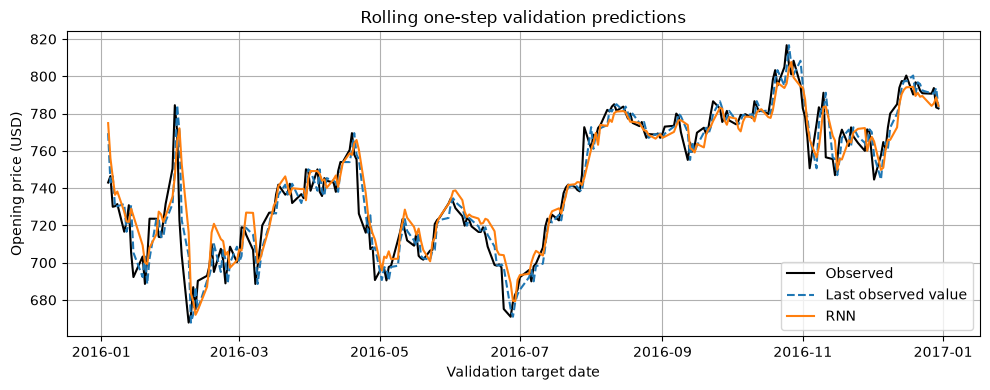

In [12]:
val_pred_scaled = model.predict(X_val, verbose=0)
val_pred = scaler.inverse_transform(val_pred_scaled)[:, 0]
validation_scores = pd.concat([
    baseline_validation,
    pd.DataFrame([error_scores(val_actual, val_pred)], index=["RNN"])
])
print(validation_scores.round(3).to_string())
print({"LOOKBACK": LOOKBACK, "UNITS": UNITS, "seed": SEED,
       "epochs_run": len(history.history["loss"]), "best_epoch": best_epoch})

plt.plot(dates[val_pos], val_actual, label="Observed", color="black")
plt.plot(dates[val_pos], val_last, label="Last observed value", linestyle="--")
plt.plot(dates[val_pos], val_pred, label="RNN")
plt.xlabel("Validation target date")
plt.ylabel("Opening price (USD)")
plt.title("Rolling one-step validation predictions")
plt.legend()
plt.tight_layout()
plt.show()


## Learner response · complete before the final test

**Shape and data explanation:** `X_train` has shape (986, 20, 1): 986 training windows (samples), 20 timesteps (the previous 20 trading days) and 1 feature (the opening price). `y_train` is (986, 1). `UNITS = 16` is not an input dimension. It is the size of the hidden state the SimpleRNN carries from step to step, so each (20, 1) window is squeezed into one vector of 16 numbers and the Dense layer turns that into the single predicted price. That is where the 305 trainable parameters come from: 16 x (1 + 16) + 16 = 288 in the recurrent layer plus 17 in Dense. The first validation example uses the 20 trading days from 3 Dec 2015 to 31 Dec 2015 and its target is the opening price on 4 Jan 2016, the first day after the training period. The first test example (target 3 Jan 2017) uses 2 Dec 2016 to 30 Dec 2016 as input. Those December days belong to the validation period, but they are real prices that were already known before the target date, so they can be inputs. Only the test targets are kept out of training. The scaler was fitted on the training rows only (minimum 279.12, maximum 776.6 USD).

**Hypothesis written before running alternatives:** I compared the supplied 20-day window with 50 days. I expected 50 days not to help. A SimpleRNN is not good at using long histories (the gradient fades over many steps), prices from two months ago say very little about tomorrow's opening price, and a longer window removes some training samples. So I expected a validation error about the same or worse than with 20 days. I also expected both networks to lose to the "last observed value" baseline, because day-to-day opening prices behave a lot like a random walk.

| Lookback | Units | Train samples | Epochs run | Validation MAE | Validation RMSE |
|---|---|---|---|---|---|
| 20 | 16 | 986 | 30 | 8.033 | 11.403 |
| 50 (chosen alternative) | 16 | 956 | 30 | 8.783 | 11.819 |

**Baseline validation scores:** persistence ("last observed value") on the same 252 validation target dates: MAE 7.157 USD, RMSE 9.852 USD. Neither RNN beats it.

**Chosen configuration and evidence:** I chose `LOOKBACK = 20`, `UNITS = 16`. On validation it has the lower MAE (8.033 vs 8.783 USD) and the lower RMSE (11.403 vs 11.819 USD). I did not look at test scores to decide this. The result matches my hypothesis: the longer window did not help. The gap is under one dollar with a single seed, so I read it as "no benefit from 50 days", not as proof that 50 is always worse.

**What remained constant?** Same chronological split (training history to 31 Dec 2015, validation targets all of 2016, test targets January 2017), seed 42, 16 units, Adam with learning rate 0.001, batch size 32, at most 30 epochs, early stopping with patience 5 and `shuffle=False`. Only `LOOKBACK` changed. The number of training samples went from 986 to 956 because each window needs 50 earlier rows instead of 20, so the first 30 targets can no longer be used. The validation (252) and test (20) targets are identical in both runs, which is what makes the scores comparable.

**Why the results look like this:**
* *Persistence is hard to beat.* Its error is simply the size of a typical one-day move (about 7 USD). To do better, the RNN would need real information about the next move, and a single past-price column does not contain much. The network also has to learn to "copy the latest price" through scaling and a 16-unit state, and any small drift away from that adds error. On validation it predicted slightly high on average (+1.48 USD), while persistence was almost unbiased (-0.05 USD).
* *The networks were still improving.* Both runs used all 30 epochs and the best epoch was epoch 30, so early stopping never triggered. The models are probably a little undertrained. I did not raise `MAX_EPOCHS`, because that would have changed a controlled setting.
* *50 days vs 20 days.* The longer window gave a slightly worse error and 30 fewer training samples. That fits the idea that old prices add noise more than signal for a next-day forecast.

## 7 · Freeze the configuration, then evaluate test once

Before this section, record the chosen settings and why validation supports them.
Use the selected model already trained above; this lab does not refit on validation data.
Do not use the final test score to choose another configuration.

The model predicts every held-out target using the actual history available immediately
before it. There is no model/scaler refitting during these trading days. All methods use exactly
the same target dates. The starter skips this section until you set `RUN_FINAL_TEST = True` after completing the core tasks.


                        MAE    RMSE
Last observed value   5.944   8.416
RNN                  10.603  12.492
Final configuration: {'LOOKBACK': 20, 'UNITS': 16, 'seed': 42, 'best_epoch': 30}
Test targets scored: 20


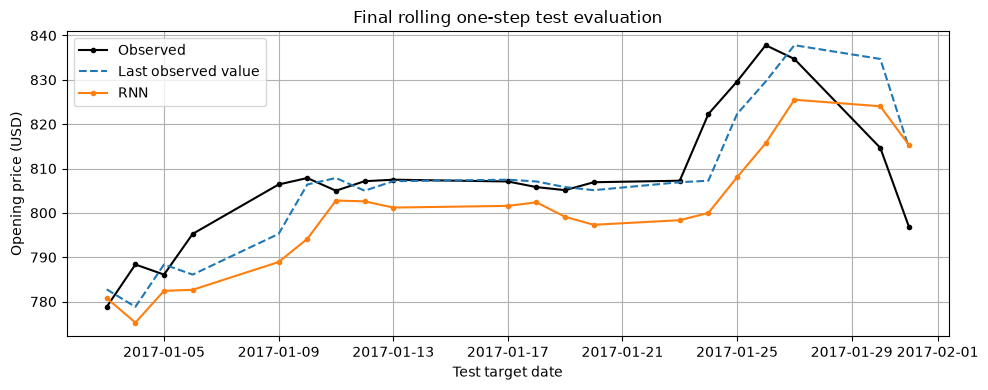

In [13]:
RUN_FINAL_TEST = True

if RUN_FINAL_TEST:
    test_actual = values[test_pos, 0].copy()
    test_last = values[test_pos - 1, 0].copy()
    test_pred = scaler.inverse_transform(model.predict(X_test, verbose=0))[:, 0]
    test_scores = pd.DataFrame({
        "Last observed value": error_scores(test_actual, test_last),
        "RNN": error_scores(test_actual, test_pred),
    }).T
    print(test_scores.round(3).to_string())
    print("Final configuration:", {"LOOKBACK": LOOKBACK, "UNITS": UNITS,
                                   "seed": SEED, "best_epoch": best_epoch})
    print("Test targets scored:", len(test_actual))

    plt.plot(dates[test_pos], test_actual, label="Observed", color="black", marker=".")
    plt.plot(dates[test_pos], test_last, label="Last observed value", linestyle="--")
    plt.plot(dates[test_pos], test_pred, label="RNN", marker=".")
    plt.xlabel("Test target date")
    plt.ylabel("Opening price (USD)")
    plt.title("Final rolling one-step test evaluation")
    plt.legend()
    plt.tight_layout()
    plt.show()
else:
    print("Test remains held out. Complete validation experiments and freeze settings first.")


## Final learner report and discussion

**Final test scores and limitation:** I set `RUN_FINAL_TEST = True` once, with the frozen configuration (`LOOKBACK = 20`, `UNITS = 16`, seed 42), on the 20 test targets from 3 Jan to 31 Jan 2017.

| Method | Test MAE (USD) | Test RMSE (USD) |
|---|---|---|
| Last observed value | 5.944 | 8.416 |
| RNN | 10.603 | 12.492 |

The simple baseline wins clearly, and the RNN is about 1.8 times as far off in MAE. This is the same picture as in validation, only larger. A likely reason is that every one of the 20 test prices is above the highest training price (776.6 USD; the scaled test values sit between 1.00 and 1.12). The network has never seen prices at that level, and its average error on the test days is -7.6 USD, so it tends to predict too low, while persistence is off by only -0.7 USD on average. The main limitation is that this is 20 days from one month with one random seed, so it says little about how either method would do in the future, and it is not evidence of a trading strategy.

**Discussion:**
* *If the actual next observation is unavailable:* the rolling one-step setup no longer works, because the input window needs yesterday's real price. We would have to forecast from a fixed starting point, either by feeding the model's own predictions back in step by step (errors pile up) or by training a model that outputs several days at once. Multi-day scores would be worse than these one-step scores and would need their own baseline, for example "repeat the last known price" for every day.
* *Why earlier test values may be used but not test targets for fitting:* in real use, by the time we predict day t, all earlier days have already happened and are known, so using them as inputs is fair. The model weights and the scaler stay fixed. Fitting on the test targets would let the model or scaler absorb the answers it is later graded on, which makes the score look better than it can be in practice.

Discuss: What changes if the actual next observation is unavailable? Why is observing earlier
test values allowed in this rolling evaluation, while fitting on test targets is not?
A short held-out period and one random seed do not establish reliable future performance.

## Optional extensions · after the core work

- Compare 8 and 32 recurrent units after fixing the window. Keep the target dates unchanged.
- Add a rolling-mean baseline using only observations before each target.
- Replace SimpleRNN with LSTM on **this same stock task**, keeping split, inputs, budget and
  metrics fixed. Do not compare its score with the airline lab to claim one architecture wins.
- Design a genuine multi-step experiment from a fixed forecast origin. If later observations
  are unknown, feed back predictions recursively or train a direct multi-output model. Evaluate
  each horizon using matching-origin baselines. The one-step score above does not measure this task.

## Sources and attribution

- Original supplied notebook attributed its tutorial to
  [moonglow22, RNN and LSTM tutorial for beginners](https://www.kaggle.com/code/moonglow22/rnn-and-lstm-tutorial-for-beginners/notebook)
  and stated Apache 2.0 for that notebook. This attribution is retained; it is not a data license.
- Data: [Kaggle dataset, version 1](https://www.kaggle.com/datasets/rahulsah06/gooogle-stock-price).
  The source metadata reports **Unknown** license. Included CSVs are source copies for review;
  see `data/DATA_SOURCES.md` in the complete pack before wider distribution.
- [Keras backend setup](https://keras.io/getting_started/),
  [MinMaxScaler](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.MinMaxScaler.html),
  [avoiding preprocessing leakage](https://scikit-learn.org/stable/common_pitfalls.html#data-leakage),
  [KaggleHub versioned downloads](https://github.com/Kaggle/kagglehub#download-dataset).
